In [2]:
!pip install tesspy geopandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 6.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 22.3 MB/s  0:00:00m0:00:0100:01
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0━━━━━━━━━━━━━━━━ 2/5 [matplotlib]
    Uninstalling matplotlib-3.10.0:━━━━━━━━━━━━━━━━━━━━━━━ 2/5 [matplotlib]
      Successfully uninstalled matplotlib-3.10.0━━━━━━━━━━━━━━━━━━ 2/5 [matplotlib]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [tesspy]2m3/5 [osmnx]tlib]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.


In [3]:
!pip install duckdb --force-reinstall --no-cache-dir --only-binary :all:

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 12.4 MB/s  0:00:02 eta 0:00:01
  Attempting uninstall: duckdb
    Found existing installation: duckdb 1.3.2
    Uninstalling duckdb-1.3.2:
      Successfully uninstalled duckdb-1.3.2


In [4]:
import duckdb
print(duckdb.__version__)  # should print a version, no error

2.0.0


In [5]:
!pip install osmium
!conda install -c conda-forge osmium-tool -y
import tesspy
import geopandas as gpd
print("tesspy ready")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 10.3 MB/s  0:00:00m0:00:01
/bin/bash: line 1: conda: command not found
tesspy ready


In [6]:
!pip install quackosm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 30.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 57.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 89.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [quackosm]8/9 [quackosm]]]


In [7]:
!pip install overturemaps

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 3.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [overturemaps]


In [8]:
import os
import geopandas as gpd
import overturemaps

# ---------------------------------------------------------------
# Config: change these two for a new city
# ---------------------------------------------------------------
CITY = "mumbai"
BBOX = (72.75, 18.88, 73.05, 19.30)   # (west, south, east, north)

BASE_DIR = f"/kaggle/working/{CITY}"

# ---------------------------------------------------------------
# Type registry: theme -> list of Overture feature types
# ---------------------------------------------------------------
THEMES = {
    "base":           ["land_cover", "land_use", "infrastructure", "land"],
    "transportation": ["segment", "connector"],
    "divisions":      ["division"],
    "water":          ["water"],
}

# ---------------------------------------------------------------
# Loop: download each type into its theme subfolder
# ---------------------------------------------------------------
summary = []

for theme, types in THEMES.items():
    theme_dir = os.path.join(BASE_DIR, theme)
    os.makedirs(theme_dir, exist_ok=True)

    for t in types:
        try:
            batch = overturemaps.record_batch_reader(t, BBOX).read_all()
            gdf = gpd.GeoDataFrame.from_arrow(batch)

            out_path = os.path.join(theme_dir, f"{CITY}_{t}.parquet")
            gdf.to_parquet(out_path)

            summary.append((theme, t, len(gdf), "ok"))
            print(f"[OK]   {theme}/{t}: {len(gdf)} rows -> {out_path}")

        except Exception as e:
            summary.append((theme, t, 0, f"FAIL: {e}"))
            print(f"[FAIL] {theme}/{t}: {e}")

# ---------------------------------------------------------------
# Report
# ---------------------------------------------------------------
print("\n=== Summary ===")
for theme, t, n, status in summary:
    print(f"{theme:15s} {t:15s} {n:>8} rows   {status}")

[OK]   base/land_cover: 2961 rows -> /kaggle/working/mumbai/base/mumbai_land_cover.parquet
[OK]   base/land_use: 13087 rows -> /kaggle/working/mumbai/base/mumbai_land_use.parquet
[OK]   base/infrastructure: 42485 rows -> /kaggle/working/mumbai/base/mumbai_infrastructure.parquet
[OK]   base/land: 8416 rows -> /kaggle/working/mumbai/base/mumbai_land.parquet
[OK]   transportation/segment: 163244 rows -> /kaggle/working/mumbai/transportation/mumbai_segment.parquet
[OK]   transportation/connector: 166143 rows -> /kaggle/working/mumbai/transportation/mumbai_connector.parquet
[OK]   divisions/division: 892 rows -> /kaggle/working/mumbai/divisions/mumbai_division.parquet
[OK]   water/water: 2738 rows -> /kaggle/working/mumbai/water/mumbai_water.parquet

=== Summary ===
base            land_cover          2961 rows   ok
base            land_use           13087 rows   ok
base            infrastructure     42485 rows   ok
base            land                8416 rows   ok
transportation  segment 

In [9]:
import os
import urllib.request

url = "https://raw.githubusercontent.com/datameet/Municipal_Spatial_Data/master/Mumbai/BMC_Wards.geojson"
out_dir = "/kaggle/working/mumbai/external"
out_path = os.path.join(out_dir, "BMC_Wards.geojson")

os.makedirs(out_dir, exist_ok=True)
urllib.request.urlretrieve(url, out_path)

print("Saved:", out_path, "| bytes:", os.path.getsize(out_path))

Saved: /kaggle/working/mumbai/external/BMC_Wards.geojson | bytes: 994699


In [10]:
import geopandas as gpd

WARDS_PATH = "/kaggle/working/mumbai/external/BMC_Wards.geojson"

# 1. Load
wards = gpd.read_file(WARDS_PATH)

# 2. Basic shape
print("Rows, cols:", wards.shape)
print("CRS:", wards.crs)

# 3. Columns (find the ward name/id field)
print("\nColumns:", list(wards.columns))

# 4. Geometry sanity
print("\nGeom types:\n", wards.geometry.geom_type.value_counts())
print("All valid:", wards.geometry.is_valid.all())
print("Empty geoms:", wards.geometry.is_empty.sum())

# 5. Bounds (should roughly match Mumbai)
print("\nBounds:", wards.total_bounds)

# 6. Peek at first few rows (non-geometry cols)
print("\nHead:\n", wards.drop(columns="geometry").head())

Rows, cols: (24, 3)
CRS: EPSG:4326

Columns: ['gid', 'name', 'geometry']

Geom types:
 MultiPolygon    24
Name: count, dtype: int64
All valid: True
Empty geoms: 0

Bounds: [72.77633295 18.89395643 72.9797315  19.27017667]

Head:
    gid name
0    1    A
1    2    B
2    3    C
3    4    D
4    5    E


In [11]:
import os
print(os.path.exists("/kaggle/working/mumbai/base/mumbai_infrastructure.parquet"))

True


In [12]:
import geopandas as gpd

infra = gpd.read_parquet("/kaggle/working/mumbai/base/mumbai_infrastructure.parquet")

# subtype distribution
print("=== subtype ===")
print(infra["subtype"].value_counts(dropna=False))

# class distribution (fallback / cross-check)
if "class" in infra.columns:
    print("\n=== class ===")
    print(infra["class"].value_counts(dropna=False).head(30))

# how many rows have geometry
print("\nTotal rows:", len(infra))
print("With geometry:", infra.geometry.notna().sum())

=== subtype ===
subtype
barrier             23650
transit              5650
transportation       3629
bridge               3185
power                2573
pedestrian           1410
utility              1010
airport               572
waste_management      247
water                 161
emergency             126
pier                  111
tower                  91
communication          52
recreation             12
manhole                 3
quay                    2
aerialway               1
Name: count, dtype: int64

=== class ===
class
gate                21201
bridge               2990
bus_stop             2698
traffic_signals      2129
power_tower          2095
wall                 1180
parking_entrance      824
crossing              757
lift_gate             743
storage_tank          728
street_lamp           672
stop_position         642
parking               549
platform              484
bench                 409
toilets               388
taxiway               375
atm                

In [13]:
import os
import geopandas as gpd

PATH = "/kaggle/working/mumbai/base/mumbai_infrastructure.parquet"

# 1. Load raw
infra = gpd.read_parquet(PATH)
print("Before prune:", len(infra), "rows | size:", os.path.getsize(PATH), "bytes")

# 2. Keep only major standalone structures
KEEP_SUBTYPES = ["airport", "tower", "pier", "quay", "recreation", "aerialway"]

# 3. Filter
pruned = infra[infra["subtype"].isin(KEEP_SUBTYPES)].copy()
print("\nAfter prune:", len(pruned), "rows")
print("\nSurviving subtypes:")
print(pruned["subtype"].value_counts(dropna=False))

# 4. Overwrite the same file (in place)
pruned.to_parquet(PATH)
print("\nOverwritten:", PATH, "| new size:", os.path.getsize(PATH), "bytes")

Before prune: 42485 rows | size: 5123242 bytes

After prune: 789 rows

Surviving subtypes:
subtype
airport       572
pier          111
tower          91
recreation     12
quay            2
aerialway       1
Name: count, dtype: int64

Overwritten: /kaggle/working/mumbai/base/mumbai_infrastructure.parquet | new size: 173147 bytes


In [19]:
import geopandas as gpd

PATH = "/kaggle/working/mumbai/base/mumbai_infrastructure.parquet"
infra = gpd.read_parquet(PATH)

# 0. Confirm source CRS before transforming
print("crs:", infra.crs)
print("bounds:", infra.total_bounds)   # expect ~72-73, 18-19 => EPSG:4326

# 1. Geometry types first — area only makes sense for polygons
print("\n=== geom_type ===")
print(infra.geometry.geom_type.value_counts())

# 2. Set CRS (Overture is 4326), then reproject to metric UTM 19N
infra_utm = infra.set_crs(4326, allow_override=True).to_crs(32619)

# 3. Fix invalid polygons before .area
infra_utm["geometry"] = infra_utm.geometry.buffer(0)

# 4. Add area (m²) and length (m)
infra_utm["area_m2"] = infra_utm.geometry.area
infra_utm["length_m"] = infra_utm.geometry.length

# 5. Per-subtype size distribution
print("\n=== size by subtype (m²) ===")
stats = infra_utm.groupby("subtype").agg(
    count=("area_m2", "size"),
    max_area=("area_m2", "max"),
    median_area=("area_m2", "median"),
    sum_area=("area_m2", "sum"),
    max_length=("length_m", "max"),
).sort_values("max_area", ascending=False)
print(stats)

# 6. Top 10 largest features overall (shortlist candidates)
print("\n=== top 10 by area ===")
print(infra_utm.nlargest(10, "area_m2")[["subtype", "class", "area_m2"]])

crs: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "degree"}]}, "scope": "Horiz

In [18]:
import os
import geopandas as gpd

PATH = "/kaggle/working/mumbai/base/mumbai_infrastructure.parquet"

# 1. Load
infra = gpd.read_parquet(PATH)
print("Before:", len(infra), "rows | size:", os.path.getsize(PATH), "bytes")

# 2. Airport rows only
apt = infra[infra["subtype"] == "airport"].copy()

# 3. Metric CRS + area
apt = apt.set_crs(4326, allow_override=True).to_crs(32619)
apt["geometry"] = apt.geometry.buffer(0)
apt["area_m2"] = apt.geometry.area

# 4. Top 3 by area
top3 = apt.nlargest(3, "area_m2").copy()

# 5. Back to 4326 for storage (consistent with the rest of the dataset)
top3 = top3.to_crs(4326)

print("\nKept:")
print(top3[["class", "area_m2"]].to_string(index=False))
print("\nAfter:", len(top3), "rows")

# 6. Overwrite same path
top3.to_parquet(PATH)
print("Overwritten:", PATH, "| new size:", os.path.getsize(PATH), "bytes")

Before: 3 rows | size: 36328 bytes

Kept:
                class      area_m2
international_airport 1.782377e+07
international_airport 7.725608e+06
              airport 1.869199e+06

After: 3 rows
Overwritten: /kaggle/working/mumbai/base/mumbai_infrastructure.parquet | new size: 36329 bytes


In [16]:
import os
import geopandas as gpd

PATH = "/kaggle/working/mumbai/base/mumbai_land.parquet"
land = gpd.read_parquet(PATH)

print("rows:", len(land), "| size:", os.path.getsize(PATH), "bytes")
print("crs:", land.crs)
print("bounds:", land.total_bounds)

# category breakdown
print("\n=== subtype ===")
print(land["subtype"].value_counts(dropna=False) if "subtype" in land.columns else "no subtype column")

if "class" in land.columns:
    print("\n=== class ===")
    print(land["class"].value_counts(dropna=False).head(30))

# geometry sanity
print("\n=== geom_type ===")
print(land.geometry.geom_type.value_counts())
print("All valid:", land.geometry.is_valid.all())

# area stats (needs metric CRS)
land_utm = land.set_crs(4326, allow_override=True).to_crs(32619)
land_utm["geometry"] = land_utm.geometry.buffer(0)
land_utm["area_m2"] = land_utm.geometry.area

print("\n=== area (m²) ===")
print(land_utm["area_m2"].describe())
print("\nLargest 5:")
print(land_utm.nlargest(5, "area_m2")[["area_m2"] + (["class"] if "class" in land.columns else [])].to_string(index=False))

rows: 8416 | size: 1777979 bytes
crs: None
bounds: [72.6526112  17.9995     74.00053042 20.0005    ]

=== subtype ===
subtype
tree        6750
forest       483
wetland      463
shrub        240
grass        224
physical     115
sand          61
land          49
rock          30
reef           1
Name: count, dtype: int64

=== class ===
class
tree             6649
wetland           463
wood              446
grassland         211
shrub             107
tree_row          101
scrub              96
cave_entrance      60
sand               41
heath              37
forest             37
peak               32
land               27
bare_rock          26
beach              20
cliff              18
grass              13
islet              12
island             10
saddle              4
shingle             2
stone               2
reef                1
hill                1
Name: count, dtype: int64

=== geom_type ===
Point           6869
Polygon         1434
LineString       108
MultiPolygon       5



LAND_USE: 13087 rows | 3376222 bytes
geom types: {'Polygon': np.int64(13053), 'MultiPolygon': np.int64(21), 'LineString': np.int64(13)}

Top 15 class:
class
residential          4616
park                 1613
construction          989
commercial            731
grass                 728
industrial            667
pitch                 666
school                411
garden                335
playground            325
recreation_ground     323
farmland              250
hospital              132
retail                118
college               115
Name: count, dtype: int64


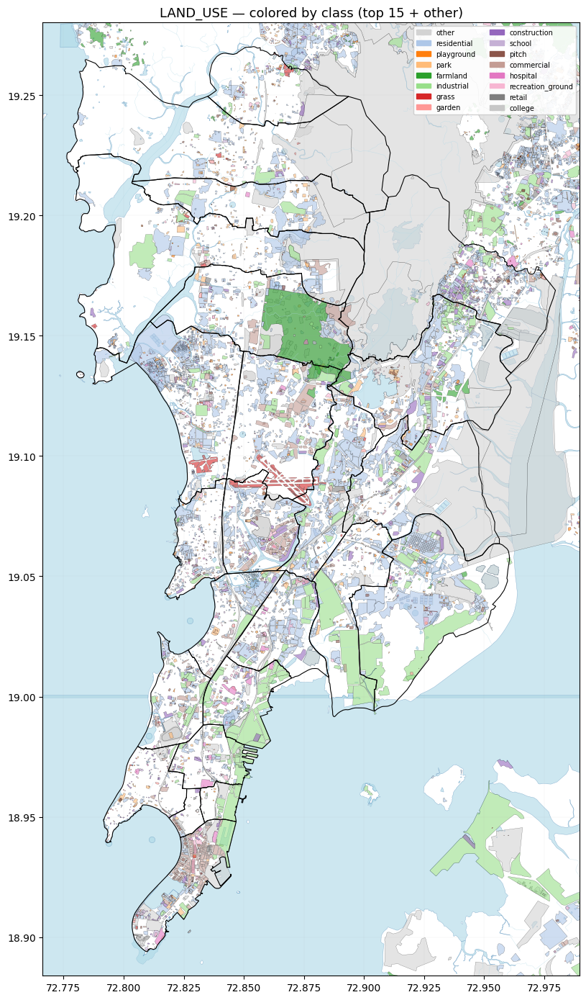


LAND_COVER: 2961 rows | 2941828 bytes
geom types: {'Polygon': np.int64(2961)}

Top 15 subtype:
subtype
barren      1024
crop         602
forest       593
shrub        334
urban        195
mangrove     115
wetland       90
grass          8
Name: count, dtype: int64


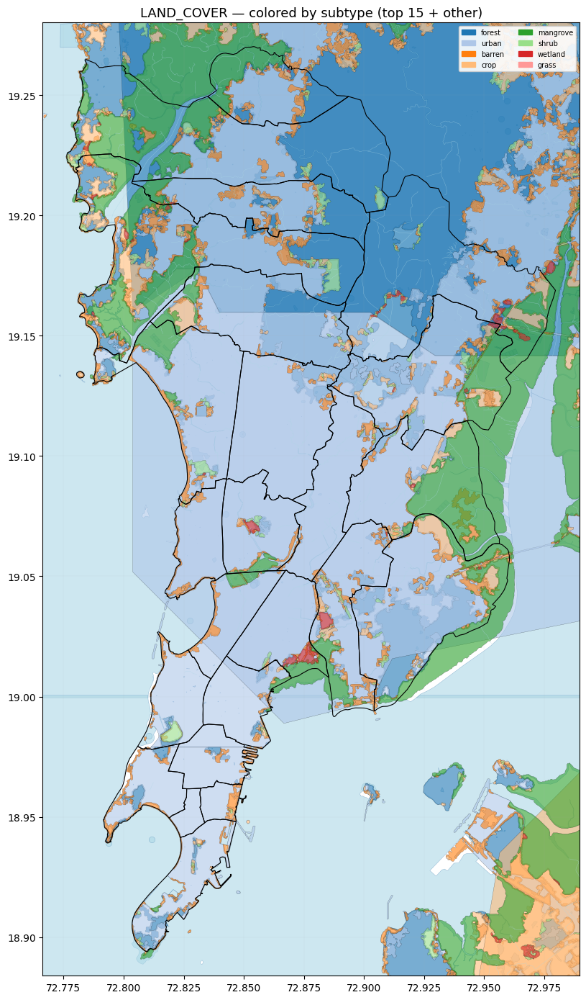

In [20]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd

WARDS_PATH = "/kaggle/working/mumbai/external/BMC_Wards.geojson"
LAND_USE_PATH = "/kaggle/working/mumbai/base/mumbai_land_use.parquet"
LAND_COVER_PATH = "/kaggle/working/mumbai/base/mumbai_land_cover.parquet"
WATER_PATH = "/kaggle/working/mumbai/water/mumbai_water.parquet"

# ---------------------------------------------------------------
# Load + ward extent (crop window)
# ---------------------------------------------------------------
wards = gpd.read_file(WARDS_PATH)
minx, miny, maxx, maxy = wards.total_bounds
pad = 0.01
extent = (minx - pad, maxx + pad, miny - pad, maxy + pad)

water = gpd.read_parquet(WATER_PATH)
if water.crs is None:
    water = water.set_crs(4326, allow_override=True)

# ---------------------------------------------------------------
# Helper: stats + plot for one layer
# ---------------------------------------------------------------
def inspect_and_plot(path, name, top_n=15):
    gdf = gpd.read_parquet(path)
    if gdf.crs is None:
        gdf = gdf.set_crs(4326, allow_override=True)

    print(f"\n{'='*50}\n{name}: {len(gdf)} rows | {os.path.getsize(path)} bytes")
    print("geom types:", dict(gdf.geometry.geom_type.value_counts()))

    col = "class" if "class" in gdf.columns else ("subtype" if "subtype" in gdf.columns else None)
    if col is None:
        print("No class/subtype column — plotting uncolored.")
        top_classes = []
        gdf["_color_key"] = "all"
    else:
        vc = gdf[col].value_counts(dropna=False)
        print(f"\nTop {top_n} {col}:")
        print(vc.head(top_n))
        top_classes = list(vc.head(top_n).index)
        gdf["_color_key"] = gdf[col].where(gdf[col].isin(top_classes), "other")

    # Plot
    fig, ax = plt.subplots(figsize=(14, 14))

    # water background
    water.plot(ax=ax, color="lightblue", edgecolor="steelblue", linewidth=0.3, alpha=0.6)

    # color by class
    keys = gdf["_color_key"].unique()
    cmap = plt.get_cmap("tab20")
    colors = {k: cmap(i % 20) for i, k in enumerate(keys)}
    if "other" in colors:
        colors["other"] = "lightgray"

    for k in keys:
        sub = gdf[gdf["_color_key"] == k]
        # polygons only for clean fill; points/lines drawn as small marks
        polys = sub[sub.geom_type.isin(["Polygon", "MultiPolygon"])]
        if len(polys):
            polys.plot(ax=ax, color=colors[k], alpha=0.6, edgecolor="black", linewidth=0.2)
        pts = sub[sub.geom_type == "Point"]
        if len(pts):
            pts.plot(ax=ax, color=colors[k], markersize=3, alpha=0.7)
        lines = sub[sub.geom_type.isin(["LineString", "MultiLineString"])]
        if len(lines):
            lines.plot(ax=ax, color=colors[k], linewidth=0.4, alpha=0.7)

    # ward outline on top
    wards.boundary.plot(ax=ax, color="black", linewidth=0.8)

    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.set_title(f"{name} — colored by {col} (top {top_n} + other)", fontsize=13)
    ax.grid(True, linewidth=0.2, alpha=0.3)

    # legend
    handles = [mpatches.Patch(color=colors[k], label=str(k)) for k in keys]
    ax.legend(handles=handles, loc="upper right", fontsize=7, ncol=2, framealpha=0.9)

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------
# Run for both layers
# ---------------------------------------------------------------
inspect_and_plot(LAND_USE_PATH, "LAND_USE")
inspect_and_plot(LAND_COVER_PATH, "LAND_COVER")

In [21]:
import os
import geopandas as gpd

LAND_USE_PATH = "/kaggle/working/mumbai/base/mumbai_land_use.parquet"
LAND_COVER_PATH = "/kaggle/working/mumbai/base/mumbai_land_cover.parquet"

# Uniform fragment cutoff: 5,000 m² (0.5 hectare). Adjust after seeing counts.
MIN_AREA_M2 = 5_000

def strip_fragments(path, label):
    gdf = gpd.read_parquet(path)
    if gdf.crs is None:
        gdf = gdf.set_crs(4326, allow_override=True)

    print(f"\n{'='*50}\n{label} — before: {len(gdf)} rows | {os.path.getsize(path)} bytes")

    # Metric CRS for real m², repair invalid polys
    gdf_utm = gdf.to_crs(32619)
    gdf_utm["geometry"] = gdf_utm.geometry.buffer(0)
    area = gdf_utm.geometry.area

    # Show distribution so you can sanity-check the cutoff
    print("area_m2 describe:\n", area.describe())

    keep = area >= MIN_AREA_M2
    kept = gdf[keep].copy()

    print(f"cutoff {MIN_AREA_M2} m² -> kept {len(kept)} rows (dropped {len(gdf)-len(kept)})")

    # Back to 4326 (consistent with rest of dataset), overwrite same path
    kept.to_parquet(path)
    print(f"overwritten: {path} | new size: {os.path.getsize(path)} bytes")
    return kept

lu = strip_fragments(LAND_USE_PATH, "LAND_USE")
lc = strip_fragments(LAND_COVER_PATH, "LAND_COVER")


LAND_USE — before: 13087 rows | 3376222 bytes


/usr/local/lib/python3.13/dist-packages/shapely/constructive.py:246: RuntimeWarning: divide by zero encountered in buffer
  return lib.buffer(
/usr/local/lib/python3.13/dist-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(


area_m2 describe:
 count    1.308700e+04
mean     5.106047e+08
std      5.840524e+10
min      0.000000e+00
25%      1.646371e+03
50%      5.301267e+03
75%      1.693751e+04
max      6.681467e+12
dtype: float64
cutoff 5000 m² -> kept 6745 rows (dropped 6342)
overwritten: /kaggle/working/mumbai/base/mumbai_land_use.parquet | new size: 2192016 bytes

LAND_COVER — before: 2961 rows | 2941828 bytes
area_m2 describe:
 count    2.961000e+03
mean     2.444348e+09
std      9.249634e+10
min      1.766850e+04
25%      2.773013e+04
50%      5.018447e+04
75%      1.338185e+05
max      4.064668e+12
dtype: float64
cutoff 5000 m² -> kept 2961 rows (dropped 0)
overwritten: /kaggle/working/mumbai/base/mumbai_land_cover.parquet | new size: 2946653 bytes


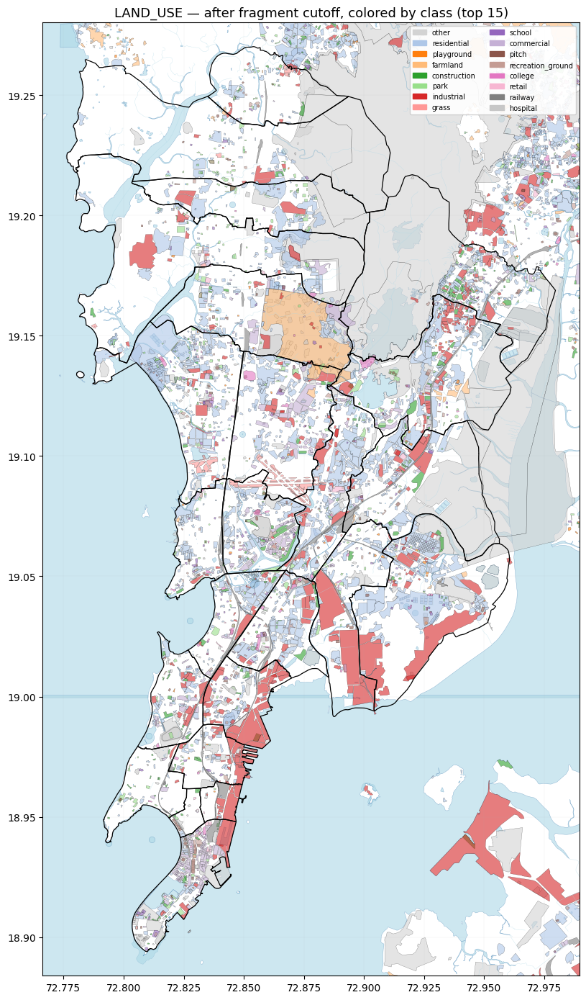

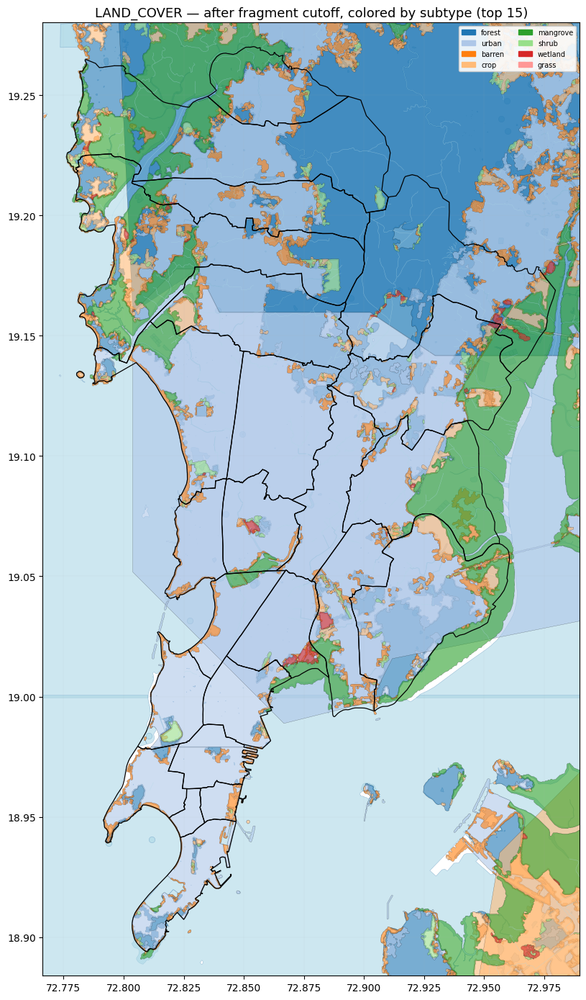

In [22]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

WARDS_PATH = "/kaggle/working/mumbai/external/BMC_Wards.geojson"
LAND_USE_PATH = "/kaggle/working/mumbai/base/mumbai_land_use.parquet"
LAND_COVER_PATH = "/kaggle/working/mumbai/base/mumbai_land_cover.parquet"
WATER_PATH = "/kaggle/working/mumbai/water/mumbai_water.parquet"

wards = gpd.read_file(WARDS_PATH)
minx, miny, maxx, maxy = wards.total_bounds
pad = 0.01
extent = (minx - pad, maxx + pad, miny - pad, maxy + pad)

water = gpd.read_parquet(WATER_PATH)
if water.crs is None:
    water = water.set_crs(4326, allow_override=True)

def plot_layer(path, name, col, top_n=15):
    gdf = gpd.read_parquet(path)
    if gdf.crs is None:
        gdf = gdf.set_crs(4326, allow_override=True)

    vc = gdf[col].value_counts(dropna=False)
    top_classes = list(vc.head(top_n).index)
    gdf["_k"] = gdf[col].where(gdf[col].isin(top_classes), "other")

    fig, ax = plt.subplots(figsize=(14, 14))
    water.plot(ax=ax, color="lightblue", edgecolor="steelblue", linewidth=0.3, alpha=0.6)

    keys = gdf["_k"].unique()
    cmap = plt.get_cmap("tab20")
    colors = {k: ("lightgray" if k == "other" else cmap(i % 20)) for i, k in enumerate(keys)}

    for k in keys:
        sub = gdf[gdf["_k"] == k]
        polys = sub[sub.geom_type.isin(["Polygon", "MultiPolygon"])]
        if len(polys):
            polys.plot(ax=ax, color=colors[k], alpha=0.6, edgecolor="black", linewidth=0.2)

    wards.boundary.plot(ax=ax, color="black", linewidth=0.9)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.set_title(f"{name} — after fragment cutoff, colored by {col} (top {top_n})", fontsize=13)
    ax.grid(True, linewidth=0.2, alpha=0.3)

    handles = [mpatches.Patch(color=colors[k], label=str(k)) for k in keys]
    ax.legend(handles=handles, loc="upper right", fontsize=7, ncol=2, framealpha=0.9)
    plt.tight_layout()
    plt.show()

plot_layer(LAND_USE_PATH, "LAND_USE", "class")
plot_layer(LAND_COVER_PATH, "LAND_COVER", "subtype")

In [25]:
import geopandas as gpd

PATH = "/kaggle/working/mumbai/base/mumbai_land_use.parquet"
lu = gpd.read_parquet(PATH)
if lu.crs is None:
    lu = lu.set_crs(4326, allow_override=True)

print("Total rows:", len(lu))
print("\nAll classes (full list, no cutoff):")
print(lu["class"].value_counts(dropna=False).to_string())

Total rows: 6745

All classes (full list, no cutoff):
class
residential                2690
industrial                  595
park                        590
commercial                  537
construction                453
school                      248
recreation_ground           181
pitch                       172
farmland                    161
grass                       139
playground                  117
railway                     110
college                      95
hospital                     76
retail                       67
garden                       53
farmyard                     42
cemetery                     38
salt_pond                    36
education                    36
military                     36
quarry                       30
greenfield                   28
university                   25
religious                    19
landfill                     18
works                        17
track                        15
pedestrian                   14
stadium     

In [ ]:
import geopandas as gpd
import pandas as pd

PATH = "/kaggle/working/mumbai/base/mumbai_land_use.parquet"
lu = gpd.read_parquet(PATH)
if lu.crs is None:
    lu = lu.set_crs(4326, allow_override=True)

# metric area
lu_utm = lu.to_crs(32619)
lu_utm["geometry"] = lu_utm.geometry.buffer(0)
lu_utm["area_m2"] = lu_utm.geometry.area

# ---- Step A: per-class area distribution ----
print("=== per-class area describe (m²) ===")
desc = lu_utm.groupby("class")["area_m2"].describe()[
    ["count", "min", "25%", "50%", "75%", "max"]
].sort_values("count", ascending=False)
print(desc.to_string())

# ---- Step B: top 3 largest polygons per class ----
print("\n=== top 3 largest per class ===")
top3 = (
    lu_utm.sort_values("area_m2", ascending=False)
    .groupby("class", group_keys=False)
    .head(3)[["class", "area_m2"]]
    .sort_values(["class", "area_m2"], ascending=[True, False])
)
print(top3.to_string(index=False))

Before: 6745 rows
After : 895 rows

Kept classes:
class
industrial           384
railway               88
construction          71
farmland              48
park                  36
farmyard              27
salt_pond             27
quarry                26
recreation_ground     21
military              21
school                21
works                 17
hospital              16
college               14
landfill              12
stadium                8
cemetery               8
university             8
nature_reserve         6
greenfield             5
education              5
garages                5
golf_course            4
grave_yard             3
zoo                    2
brownfield             2
theme_park             2
national_park          1
water_park             1
religious              1
range                  1
plant_nursery          1
airfield               1
institutional          1
naval_base             1


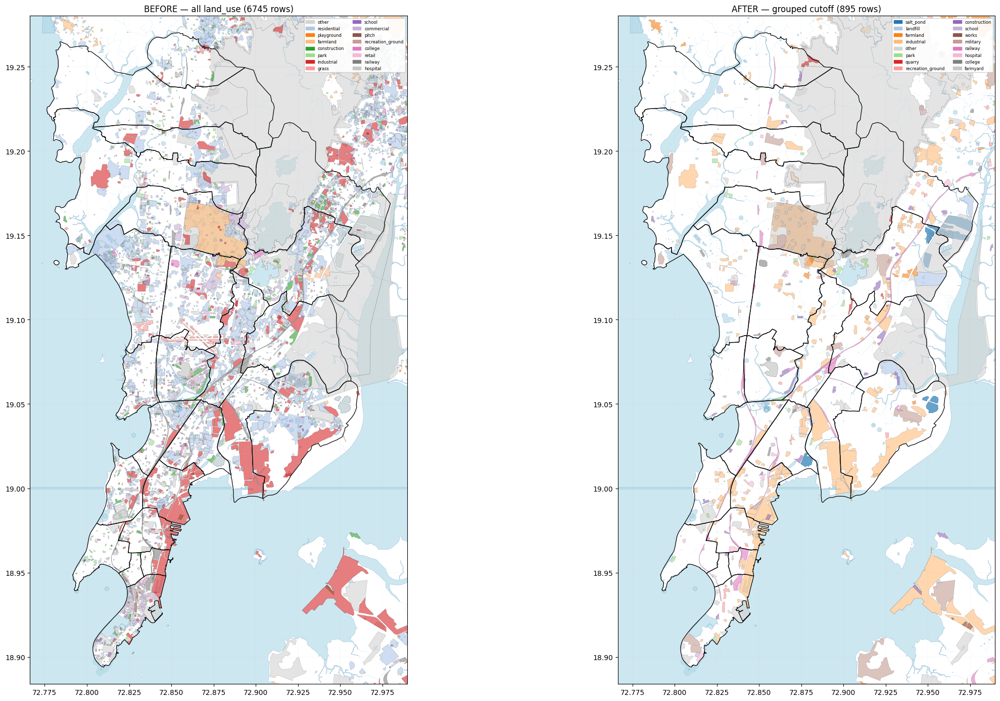

In [27]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

PATH = "/kaggle/working/mumbai/base/mumbai_land_use.parquet"
WARDS_PATH = "/kaggle/working/mumbai/external/BMC_Wards.geojson"
WATER_PATH = "/kaggle/working/mumbai/water/mumbai_water.parquet"

lu = gpd.read_parquet(PATH)
if lu.crs is None:
    lu = lu.set_crs(4326, allow_override=True)

wards = gpd.read_file(WARDS_PATH)
water = gpd.read_parquet(WATER_PATH)
if water.crs is None:
    water = water.set_crs(4326, allow_override=True)

# crop window = ward bounds + pad
minx, miny, maxx, maxy = wards.total_bounds
pad = 0.01
extent = (minx - pad, maxx + pad, miny - pad, maxy + pad)

# ---------------------------------------------------------------
# grouped cutoff rules: class -> min area (m²)
# classes not listed here are DROPPED
# ---------------------------------------------------------------
CUTOFF = {
    # institutional
    "school": 30_000, "college": 50_000, "university": 100_000,
    "hospital": 50_000, "education": 50_000, "religious": 50_000,
    "institutional": 0,
    # industrial / operational
    "industrial": 30_000, "railway": 30_000, "quarry": 50_000,
    "landfill": 30_000, "salt_pond": 30_000, "military": 50_000,
    "works": 0, "farmyard": 30_000, "garages": 20_000,
    # green / recreation big
    "park": 50_000, "recreation_ground": 50_000, "stadium": 50_000,
    "cemetery": 30_000, "grave_yard": 20_000,
    "nature_reserve": 0, "national_park": 0, "golf_course": 0,
    "zoo": 0, "theme_park": 0, "water_park": 0, "airfield": 0,
    "naval_base": 0, "range": 0, "brownfield": 50_000,
    "greenfield": 50_000, "plant_nursery": 20_000,
    "farmland": 50_000, "construction": 50_000,
}

# metric area for filtering
lu_utm = lu.to_crs(32619)
lu_utm["geometry"] = lu_utm.geometry.buffer(0)
lu_utm["area_m2"] = lu_utm.geometry.area

# apply rule
def keep(row):
    c = row["class"]
    if c not in CUTOFF:
        return False
    return row["area_m2"] >= CUTOFF[c]

mask = lu_utm.apply(keep, axis=1)
lu_kept = lu[mask.values].copy()

print("Before:", len(lu), "rows")
print("After :", len(lu_kept), "rows")
print("\nKept classes:")
print(lu_kept["class"].value_counts().to_string())

# ---------------------------------------------------------------
# Plot before / after side by side
# ---------------------------------------------------------------
def plot(gdf, ax, title):
    water.plot(ax=ax, color="lightblue", edgecolor="steelblue", linewidth=0.3, alpha=0.6)

    # color by class (top 15 + other)
    vc = gdf["class"].value_counts()
    top = list(vc.head(15).index)
    gdf = gdf.copy()
    gdf["_k"] = gdf["class"].where(gdf["class"].isin(top), "other")

    cmap = plt.get_cmap("tab20")
    keys = list(gdf["_k"].unique())
    colors = {k: ("lightgray" if k == "other" else cmap(i % 20)) for i, k in enumerate(keys)}

    for k in keys:
        sub = gdf[gdf["_k"] == k]
        sub.plot(ax=ax, color=colors[k], alpha=0.6, edgecolor="black", linewidth=0.15)

    wards.boundary.plot(ax=ax, color="black", linewidth=0.9)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=12)
    ax.grid(True, linewidth=0.2, alpha=0.3)

    handles = [mpatches.Patch(color=colors[k], label=str(k)) for k in keys]
    ax.legend(handles=handles, loc="upper right", fontsize=6, ncol=2, framealpha=0.9)

fig, axes = plt.subplots(1, 2, figsize=(26, 14))
plot(lu, axes[0], f"BEFORE — all land_use ({len(lu)} rows)")
plot(lu_kept, axes[1], f"AFTER — grouped cutoff ({len(lu_kept)} rows)")
plt.tight_layout()
plt.show()

land_use BEFORE: 6745 | AFTER: 895
roads plotted: 17252


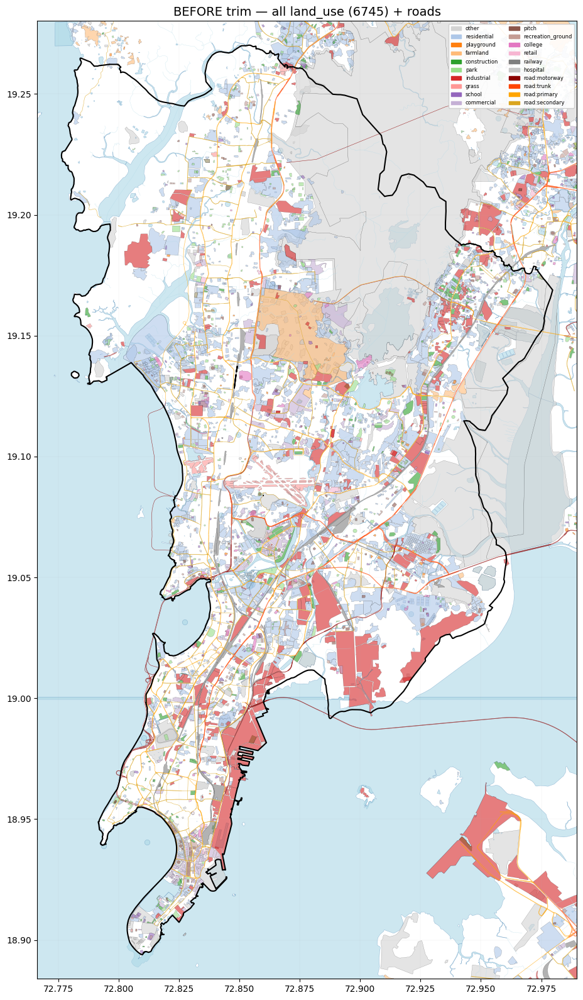

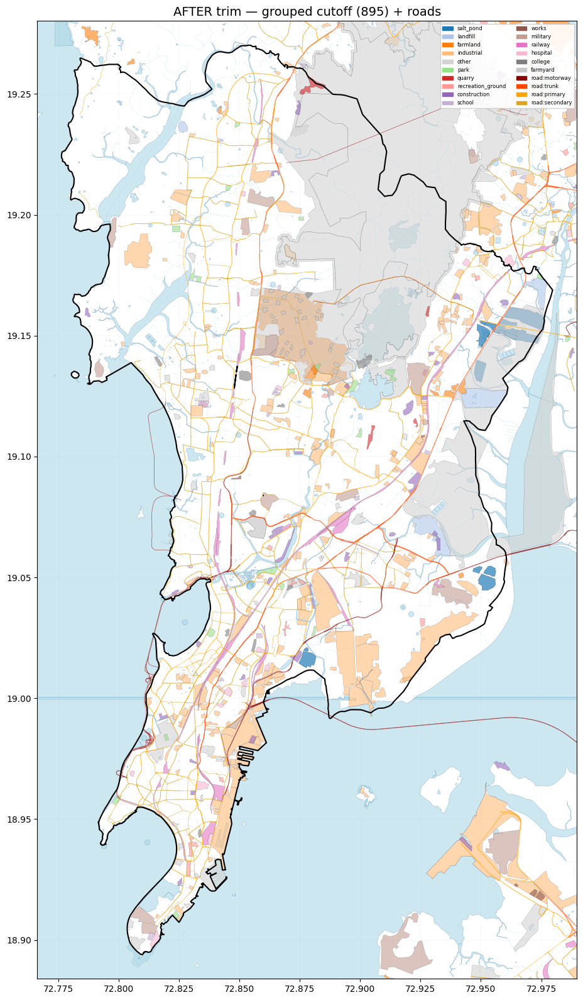

In [28]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ---- paths ----
LU_PATH     = "/kaggle/working/mumbai/base/mumbai_land_use.parquet"
SEG_PATH    = "/kaggle/working/mumbai/transportation/mumbai_segment.parquet"
WARDS_PATH  = "/kaggle/working/mumbai/external/BMC_Wards.geojson"
WATER_PATH  = "/kaggle/working/mumbai/water/mumbai_water.parquet"

# ---- load ----
lu = gpd.read_parquet(LU_PATH)
seg = gpd.read_parquet(SEG_PATH)
wards = gpd.read_file(WARDS_PATH)
water = gpd.read_parquet(WATER_PATH)
for g in (lu, seg, water):
    if g.crs is None:
        g.set_crs(4326, allow_override=True, inplace=True)

# ---- dissolve wards -> single Mumbai outline ----
mumbai_boundary = wards.dissolve()

# ---- crop window from dissolved outline ----
minx, miny, maxx, maxy = mumbai_boundary.total_bounds
pad = 0.01
extent = (minx - pad, maxx + pad, miny - pad, maxy + pad)

# ---- road classes (adjust names to match your data) ----
ROAD_CLASSES = ["motorway", "trunk", "primary", "secondary"]
ROAD_COLORS = {
    "motorway":  "darkred",
    "trunk":     "orangered",
    "primary":   "orange",
    "secondary": "goldenrod",
}
seg_col = "class" if "class" in seg.columns else "subtype"
roads = seg[seg[seg_col].isin(ROAD_CLASSES)].copy()

# ---- grouped cutoff (same dict as before) ----
CUTOFF = {
    "school": 30_000, "college": 50_000, "university": 100_000,
    "hospital": 50_000, "education": 50_000, "religious": 50_000,
    "institutional": 0,
    "industrial": 30_000, "railway": 30_000, "quarry": 50_000,
    "landfill": 30_000, "salt_pond": 30_000, "military": 50_000,
    "works": 0, "farmyard": 30_000, "garages": 20_000,
    "park": 50_000, "recreation_ground": 50_000, "stadium": 50_000,
    "cemetery": 30_000, "grave_yard": 20_000,
    "nature_reserve": 0, "national_park": 0, "golf_course": 0,
    "zoo": 0, "theme_park": 0, "water_park": 0, "airfield": 0,
    "naval_base": 0, "range": 0, "brownfield": 50_000,
    "greenfield": 50_000, "plant_nursery": 20_000,
    "farmland": 50_000, "construction": 50_000,
}

lu_utm = lu.to_crs(32619)
lu_utm["geometry"] = lu_utm.geometry.buffer(0)
lu_utm["area_m2"] = lu_utm.geometry.area
mask = lu_utm.apply(
    lambda r: r["class"] in CUTOFF and r["area_m2"] >= CUTOFF[r["class"]],
    axis=1,
)
lu_after = lu[mask.values].copy()

print("land_use BEFORE:", len(lu), "| AFTER:", len(lu_after))
print("roads plotted:", len(roads))

# ---- plotting helper ----
def draw(gdf_lu, title):
    fig, ax = plt.subplots(figsize=(16, 16))

    # water background
    water.plot(ax=ax, color="lightblue", edgecolor="steelblue", linewidth=0.3, alpha=0.6)

    # land_use (top 15 class + other)
    vc = gdf_lu["class"].value_counts()
    top = list(vc.head(15).index)
    g = gdf_lu.copy()
    g["_k"] = g["class"].where(g["class"].isin(top), "other")
    cmap = plt.get_cmap("tab20")
    keys = list(g["_k"].unique())
    colors = {k: ("lightgray" if k == "other" else cmap(i % 20)) for i, k in enumerate(keys)}
    for k in keys:
        sub = g[g["_k"] == k]
        sub.plot(ax=ax, color=colors[k], alpha=0.6, edgecolor="black", linewidth=0.15)

    # roads — 4 classes
    for cls, col in ROAD_COLORS.items():
        r = roads[roads[seg_col] == cls]
        if len(r):
            r.plot(ax=ax, color=col, linewidth=0.4, alpha=0.8)

    # single Mumbai outline
    mumbai_boundary.boundary.plot(ax=ax, color="black", linewidth=1.5)

    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=14)
    ax.grid(True, linewidth=0.2, alpha=0.3)

    # legend: land_use classes + road classes
    lu_handles = [mpatches.Patch(color=colors[k], label=str(k)) for k in keys]
    road_handles = [mpatches.Patch(color=c, label=f"road:{k}") for k, c in ROAD_COLORS.items()]
    ax.legend(handles=lu_handles + road_handles, loc="upper right",
              fontsize=6, ncol=2, framealpha=0.9)
    plt.tight_layout()
    plt.show()

# ---- Figure 1: BEFORE trim ----
draw(lu, f"BEFORE trim — all land_use ({len(lu)}) + roads")

# ---- Figure 2: AFTER trim ----
draw(lu_after, f"AFTER trim — grouped cutoff ({len(lu_after)}) + roads")

land_use BEFORE: 6745 | AFTER: 895
roads plotted: 33560


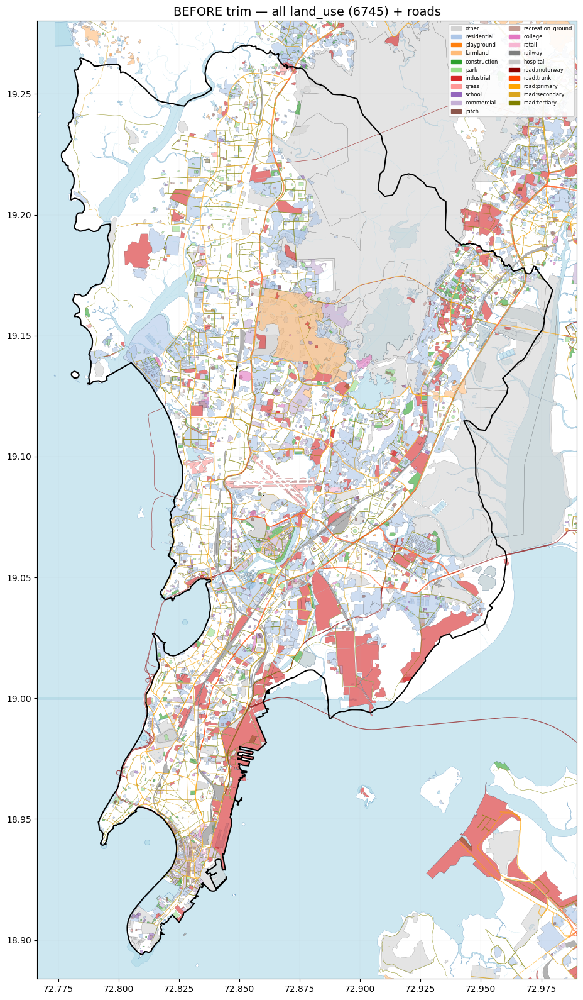

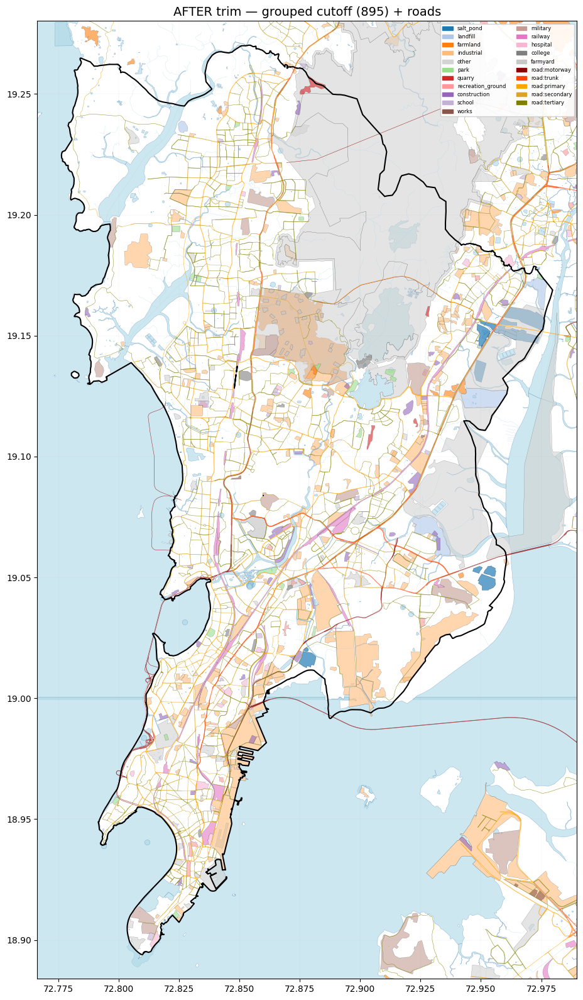

In [29]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ---- paths ----
LU_PATH     = "/kaggle/working/mumbai/base/mumbai_land_use.parquet"
SEG_PATH    = "/kaggle/working/mumbai/transportation/mumbai_segment.parquet"
WARDS_PATH  = "/kaggle/working/mumbai/external/BMC_Wards.geojson"
WATER_PATH  = "/kaggle/working/mumbai/water/mumbai_water.parquet"

# ---- load ----
lu = gpd.read_parquet(LU_PATH)
seg = gpd.read_parquet(SEG_PATH)
wards = gpd.read_file(WARDS_PATH)
water = gpd.read_parquet(WATER_PATH)
for g in (lu, seg, water):
    if g.crs is None:
        g.set_crs(4326, allow_override=True, inplace=True)

# ---- dissolve wards -> single Mumbai outline ----
mumbai_boundary = wards.dissolve()

# ---- crop window from dissolved outline ----
minx, miny, maxx, maxy = mumbai_boundary.total_bounds
pad = 0.01
extent = (minx - pad, maxx + pad, miny - pad, maxy + pad)

# ---- road classes (now includes tertiary) ----
ROAD_CLASSES = ["motorway", "trunk", "primary", "secondary", "tertiary"]
ROAD_COLORS = {
    "motorway":  "darkred",
    "trunk":     "orangered",
    "primary":   "orange",
    "secondary": "goldenrod",
    "tertiary":  "olive",
}
seg_col = "class" if "class" in seg.columns else "subtype"
roads = seg[seg[seg_col].isin(ROAD_CLASSES)].copy()

# ---- grouped cutoff (same dict as before) ----
CUTOFF = {
    "school": 30_000, "college": 50_000, "university": 100_000,
    "hospital": 50_000, "education": 50_000, "religious": 50_000,
    "institutional": 0,
    "industrial": 30_000, "railway": 30_000, "quarry": 50_000,
    "landfill": 30_000, "salt_pond": 30_000, "military": 50_000,
    "works": 0, "farmyard": 30_000, "garages": 20_000,
    "park": 50_000, "recreation_ground": 50_000, "stadium": 50_000,
    "cemetery": 30_000, "grave_yard": 20_000,
    "nature_reserve": 0, "national_park": 0, "golf_course": 0,
    "zoo": 0, "theme_park": 0, "water_park": 0, "airfield": 0,
    "naval_base": 0, "range": 0, "brownfield": 50_000,
    "greenfield": 50_000, "plant_nursery": 20_000,
    "farmland": 50_000, "construction": 50_000,
}

lu_utm = lu.to_crs(32619)
lu_utm["geometry"] = lu_utm.geometry.buffer(0)
lu_utm["area_m2"] = lu_utm.geometry.area
mask = lu_utm.apply(
    lambda r: r["class"] in CUTOFF and r["area_m2"] >= CUTOFF[r["class"]],
    axis=1,
)
lu_after = lu[mask.values].copy()

print("land_use BEFORE:", len(lu), "| AFTER:", len(lu_after))
print("roads plotted:", len(roads))

# ---- plotting helper ----
def draw(gdf_lu, title):
    fig, ax = plt.subplots(figsize=(16, 16))

    water.plot(ax=ax, color="lightblue", edgecolor="steelblue", linewidth=0.3, alpha=0.6)

    # land_use (top 15 class + other)
    vc = gdf_lu["class"].value_counts()
    top = list(vc.head(15).index)
    g = gdf_lu.copy()
    g["_k"] = g["class"].where(g["class"].isin(top), "other")
    cmap = plt.get_cmap("tab20")
    keys = list(g["_k"].unique())
    colors = {k: ("lightgray" if k == "other" else cmap(i % 20)) for i, k in enumerate(keys)}
    for k in keys:
        sub = g[g["_k"] == k]
        sub.plot(ax=ax, color=colors[k], alpha=0.6, edgecolor="black", linewidth=0.15)

    # roads — 5 classes
    for cls, col in ROAD_COLORS.items():
        r = roads[roads[seg_col] == cls]
        if len(r):
            r.plot(ax=ax, color=col, linewidth=0.4, alpha=0.8)

    # single Mumbai outline
    mumbai_boundary.boundary.plot(ax=ax, color="black", linewidth=1.5)

    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=14)
    ax.grid(True, linewidth=0.2, alpha=0.3)

    lu_handles = [mpatches.Patch(color=colors[k], label=str(k)) for k in keys]
    road_handles = [mpatches.Patch(color=c, label=f"road:{k}") for k, c in ROAD_COLORS.items()]
    ax.legend(handles=lu_handles + road_handles, loc="upper right",
              fontsize=6, ncol=2, framealpha=0.9)
    plt.tight_layout()
    plt.show()

# ---- Figure 1: BEFORE trim ----
draw(lu, f"BEFORE trim — all land_use ({len(lu)}) + roads")

# ---- Figure 2: AFTER trim ----
draw(lu_after, f"AFTER trim — grouped cutoff ({len(lu_after)}) + roads")